# 미니프로젝트: 회귀 및 분류 모델링 (Vibe Coding)

#### <목표>
Day 2에서 배운 **다중선형회귀, Ridge·Lasso, 로지스틱 회귀, 의사결정나무**를 새로운 제조 데이터셋에 적용해 봅니다.

**Cursor AI**를 활용하여 각 단계의 코드를 직접 생성하고 실행해 보세요.

#### <데이터셋 소개>

**1) 회귀용 — Mining Process Flotation Plant (광물 선광 공정 데이터)**
- 철광석을 선광(flotation)하는 공정에서 1시간 간격으로 수집된 실제 산업 데이터 (2017.03~2017.09)
- 공정 변수로 최종 정광의 불순물(실리카) 비율을 예측

| 변수명 | 설명 |
|:---:|:---|
| date | 측정 일시 |
| % Iron Feed, % Silica Feed | 투입 원광의 철/실리카 품위 |
| Starch Flow, Amina Flow | 전분/아민 투입량 (시약) |
| Ore Pulp Flow, pH, Density | 광액 유량/산도/밀도 |
| Flotation Column 01~07 Air Flow | 플로테이션 컬럼별 공기 유량 |
| Flotation Column 01~07 Level | 플로테이션 컬럼별 액위 |
| % Iron Concentrate | 최종 정광의 철 비율 (실험실 측정) |
| **% Silica Concentrate** | **최종 정광의 실리카(불순물) 비율 — 회귀 타겟** |

**2) 분류용 — Steel Plates Faults (철강 표면 결함 검사 데이터)**
- 철강판 표면을 촬영해 측정한 결함의 위치/크기/광도 등으로 결함 유형을 분류하는 실제 품질검사 데이터

| 변수명 | 설명 |
|:---:|:---|
| X/Y_Minimum, X/Y_Maximum | 결함의 위치 범위 |
| Pixels_Areas, X/Y_Perimeter | 결함의 면적·둘레 |
| Sum/Minimum/Maximum_of_Luminosity | 결함 부위의 광도 |
| Length_of_Conveyer, Steel_Plate_Thickness | 설비/소재 정보 |
| TypeOfSteel_A300, TypeOfSteel_A400 | 철강 타입 |
| Edges_Index, Square_Index, Luminosity_Index 등 | 결함 형태 특징 지수 |
| Pastry, Z_Scratch, K_Scatch, Stains, Dirtiness, Bumps, Other_Faults | 결함 유형 |
| **K_Scatch** | **긴 스크래치성 결함 여부 — 분류 타겟** |

#### <실습 태스크>
| 태스크 | 데이터 파일 | 타겟 변수 | 사용 모델 |
|:---:|:---:|:---:|:---|
| 회귀 | `dataset/day2_miniproject_reg.csv` | `% Silica Concentrate` | 다중선형회귀, Ridge, Lasso, 의사결정나무 회귀 |
| 분류 | `dataset/day2_miniproject_cls.csv` | `K_Scatch` (재구성 필요) | 로지스틱 회귀, 의사결정나무 분류 |

#### <진행 순서>
**Part A(회귀)** 를 데이터 불러오기 → 탐색 → 전처리 → 모델링 → 예측 → 고도화 → 결과 해석까지 **끝까지 완료한 뒤**, **Part B(분류)** 를 동일한 흐름으로 진행합니다.

1. 각 섹션의 **과제**를 읽고, 어떤 고민/결정이 필요한지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

**[과제]** 써니는 이번에는 제조 공정 데이터를 가지고 회귀와 분류를 모두 다뤄야 합니다. 분석에 필요한 라이브러리를 AI와 상의해서 불러오세요.

In [17]:
# ============================================================
# 0) 분석 준비 — 라이브러리 불러오기
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

# 데이터 처리
import numpy as np
import pandas as pd

# 시각화 (EDA + 모델 결과 해석)
import matplotlib.pyplot as plt
import seaborn as sns

# 머신러닝 — 데이터 분할·전처리
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 머신러닝 — 회귀 모델
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

# 머신러닝 — 분류 모델
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree  # 의사결정나무 시각화(plot_tree)

# 머신러닝 — 회귀 평가 지표
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

from statsmodels.stats.outliers_influence import variance_inflation_factor

# 머신러닝 — 분류 평가 지표
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

# ============================================================
# 시각화 기본 설정
# ============================================================
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지
sns.set_theme(style="whitegrid", palette="muted")

# pandas 출력 옵션 (EDA 시 표 확인용)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("라이브러리 로드 완료")

라이브러리 로드 완료


In [5]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part A. 회귀 태스크 — Mining Process Flotation Plant

## A-0) 데이터 불러오기

**[과제]** 써니는 `dataset/day2_miniproject_reg.csv` 파일을 불러오려고 합니다. 적절한 변수명으로 데이터프레임을 만들어 보세요.

In [6]:
# Part A — 회귀 (Mining Process Flotation Plant)
df_reg = pd.read_csv("dataset/day2_miniproject_reg.csv", parse_dates=["date"])

# Part B — 분류 (Steel Plates Faults)
df_cls = pd.read_csv("dataset/day2_miniproject_cls.csv")

---
## A-1) 데이터 탐색 (EDA)

### A-1-1) Value 기반 탐색

**[과제]** 써니는 데이터에 대한 이해 없이 모델링을 진행하는 것이 불안합니다. AI와 함께 데이터의 어떤 특성을 먼저 확인해야 하는지 논의하고, 실제로 데이터를 탐색하여 분석에 필요한 인사이트를 도출해 보세요.

In [10]:
def basic_overview(df, name="df"):
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("\n[dtypes]")
    print(df.dtypes)
    print("\n[missing]")
    print(df.isnull().sum())
    print("\n[duplicated rows]", df.duplicated().sum())
    print("\n[nunique]")
    print(df.nunique().sort_values())

basic_overview(df_reg, "선형")
basic_overview(df_cls, "분류형")


===== 선형 =====
shape: (3948, 24)

[dtypes]
date                            datetime64[ns]
% Iron Feed                            float64
% Silica Feed                          float64
Starch Flow                            float64
Amina Flow                             float64
Ore Pulp Flow                          float64
Ore Pulp pH                            float64
Ore Pulp Density                       float64
Flotation Column 01 Air Flow           float64
Flotation Column 02 Air Flow           float64
Flotation Column 03 Air Flow           float64
Flotation Column 04 Air Flow           float64
Flotation Column 05 Air Flow           float64
Flotation Column 06 Air Flow           float64
Flotation Column 07 Air Flow           float64
Flotation Column 01 Level              float64
Flotation Column 02 Level              float64
Flotation Column 03 Level              float64
Flotation Column 04 Level              float64
Flotation Column 05 Level              float64
Flotation Column

In [13]:
df_reg.head(10)

,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,Flotation Column 03 Air Flow,Flotation Column 04 Air Flow,Flotation Column 05 Air Flow,Flotation Column 06 Air Flow,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-29 12:00:00,60.1800,9.3400,"1,060.8593",379.8362,400.9825,9.5272,1.5504,200.0358,195.5777,199.9837,295.0960,306.4000,250.0697,249.9930,753.7242,726.5594,860.5578,477.3492,452.5125,478.2196,470.1055,66.4400,1.3600
1,2017-03-29 13:00:00,60.1800,9.3400,"2,034.9265",322.2340,400.4689,9.7007,1.5320,199.9901,195.1062,199.7653,295.0960,306.4000,250.0291,250.0597,848.6755,777.7844,869.4194,483.8161,469.4482,471.6071,462.6655,66.5700,1.4300
2,2017-03-29 14:00:00,60.1800,9.3400,"1,435.4258",474.6563,399.1571,9.6878,1.6452,200.0193,195.6049,199.9258,295.0960,306.4000,249.9794,250.1113,851.9515,776.2937,879.7050,456.1472,453.2270,447.7085,453.4757,66.6400,1.3300
3,2017-03-29 15:00:00,60.1800,9.3400,618.4604,396.3777,398.9425,9.8517,1.5599,199.9408,195.6571,200.0443,295.0960,306.4000,249.9786,250.0285,855.9106,780.3699,882.0939,449.4107,448.5815,450.6976,448.6601,66.4100,1.2700
4,2017-03-29 16:00:00,59.5400,9.5600,"1,367.5029",317.1341,400.8363,9.9362,1.5310,199.8789,196.1629,199.9055,295.0960,306.4000,250.0617,250.1221,851.6035,784.4461,884.8407,450.1230,451.7747,451.5744,449.4069,63.6300,5.5000
5,2017-03-29 17:00:00,59.5400,9.5600,"1,729.4127",410.9787,400.0361,9.4770,1.5677,199.9062,195.2356,200.0276,295.0960,306.4000,250.0245,250.0532,847.6022,803.1983,869.1788,431.9779,452.8780,462.7903,449.5860,66.1900,1.6400
6,2017-03-29 18:00:00,59.5400,9.5600,"1,639.5992",460.2168,399.2554,9.6049,1.6268,199.9013,195.5469,199.8719,295.0960,306.4000,249.9974,250.0764,856.0261,820.4411,883.4085,336.0238,449.6954,452.2069,449.9734,66.2600,1.4600
7,2017-03-29 19:00:00,59.5400,9.5600,"1,913.0138",495.2351,399.9483,9.5585,1.6735,199.8669,195.5666,200.0535,295.0960,306.4000,250.0070,250.0362,855.8632,818.4811,882.9910,559.4628,556.9675,518.0529,523.2317,66.2800,1.6900
8,2017-03-29 20:00:00,59.5400,9.5600,"2,033.8157",500.4932,400.5125,9.2799,1.6829,199.8982,195.3800,199.8605,295.0960,306.4000,250.0677,250.0158,855.7004,816.5212,883.0138,589.5073,601.7241,549.2019,548.9722,64.1300,1.8100
9,2017-03-29 21:00:00,59.5400,9.5600,"2,213.6027",530.6426,400.3550,9.5883,1.7217,199.8808,195.3748,199.9189,295.0960,306.4000,250.0176,250.2134,855.5376,814.5613,884.3857,589.1645,603.1319,549.1781,552.9522,65.8800,1.7100


### A-1-2) Graph 기반 탐색

**[과제]** 써니는 데이터를 살펴보던 중 변수들이 시간에 따라 수집된 값이라는 사실을 확인했습니다. 이에 따라 시간의 흐름에 따라 각 변수의 값이 어떻게 변화하는지 궁금해졌습니다. AI와 함께 시계열 데이터에 적합한 시각화 방법을 논의하고 변수별 변화를 직접 시각화하여 데이터에서 발견한 특징과 인사이트를 정리해 보세요.

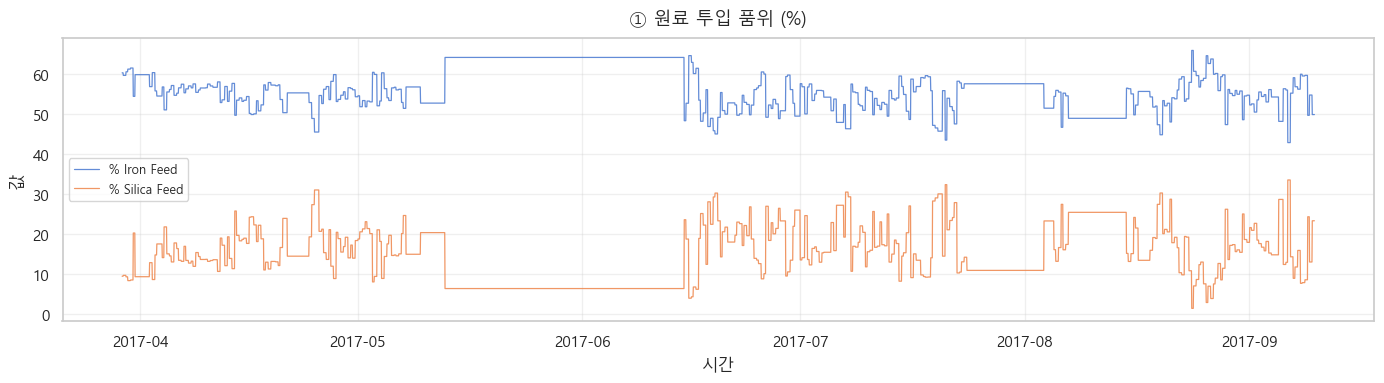

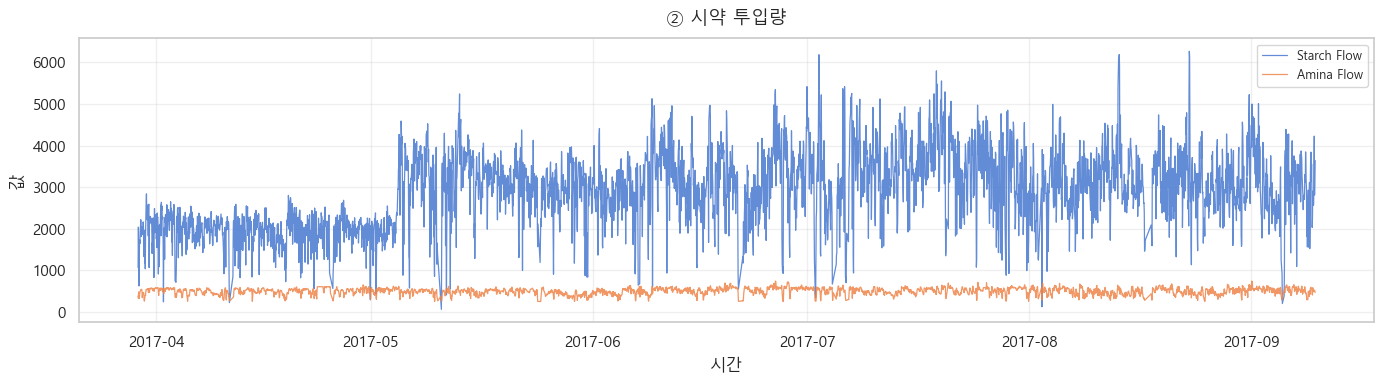

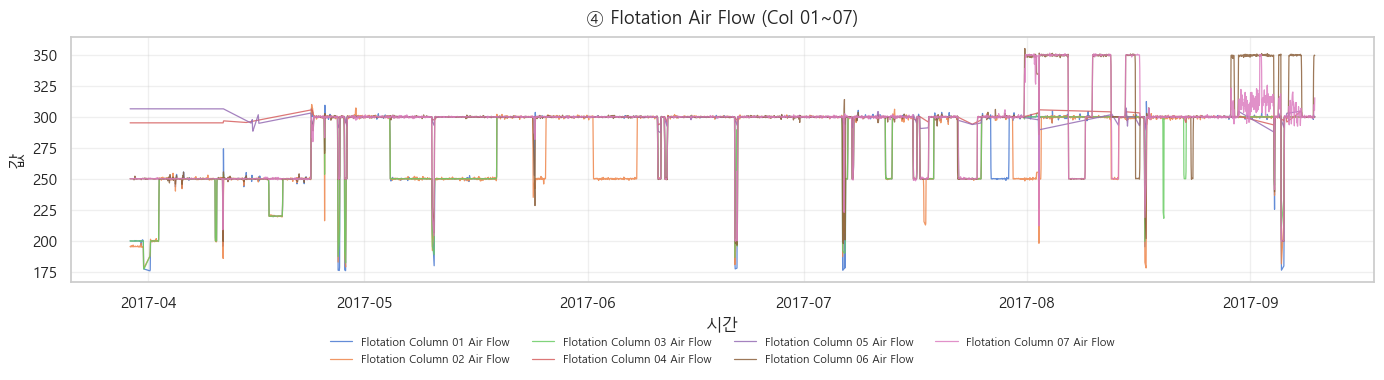

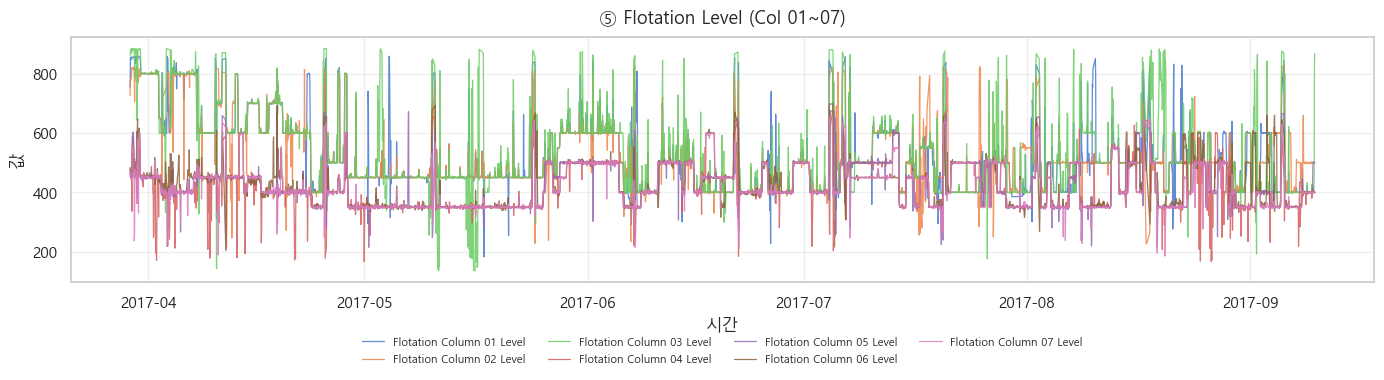

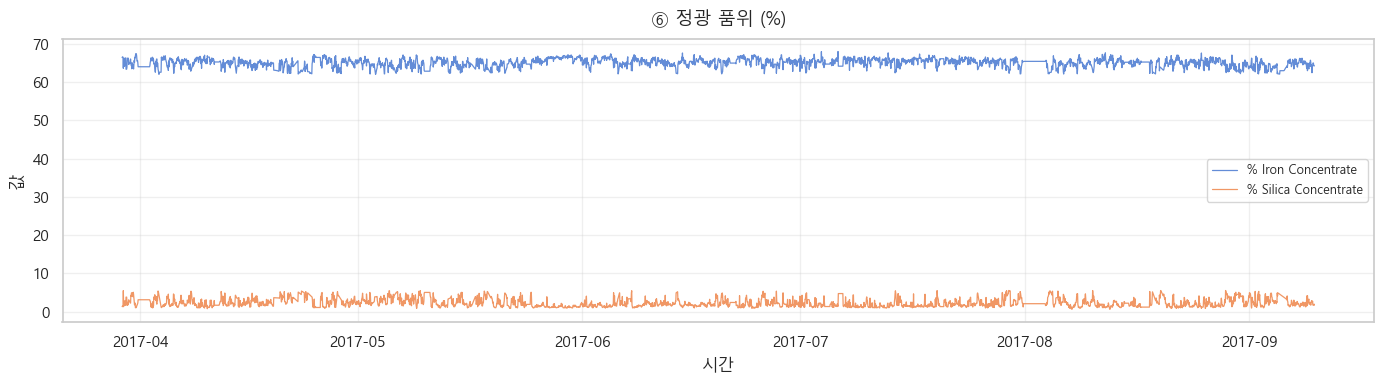

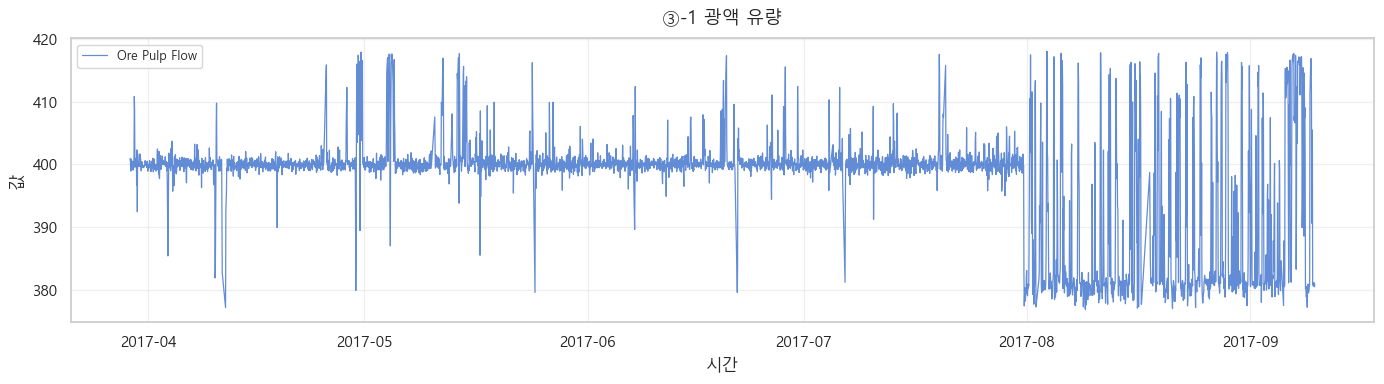

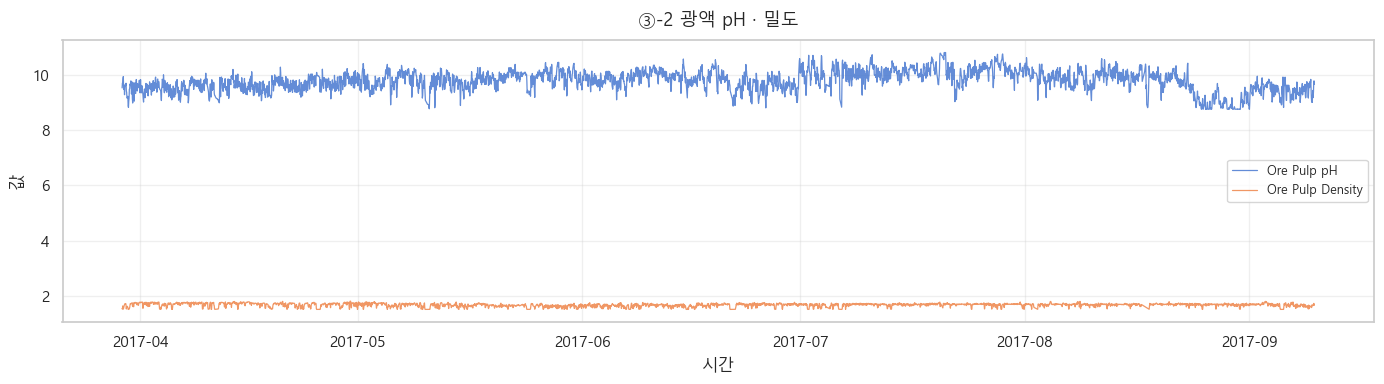

In [14]:
# ============================================================
# 시계열 Line Plot — 유사 범위 변수끼리 그룹화
# ============================================================

# date를 인덱스로 (이미 시간순이라고 가정)
df_ts = df_reg.set_index("date").sort_index()

# 그룹 정의: 의미 + 값 범위가 비슷한 변수끼리 묶음
plot_groups = {
    "① 원료 투입 품위 (%)": [
        "% Iron Feed",
        "% Silica Feed",
    ],
    "② 시약 투입량": [
        "Starch Flow",
        "Amina Flow",
    ],
    "③ 광액 조건": [
        "Ore Pulp Flow",
        "Ore Pulp pH",
        "Ore Pulp Density",
    ],
    "④ Flotation Air Flow (Col 01~07)": [
        f"Flotation Column {i:02d} Air Flow" for i in range(1, 8)
    ],
    "⑤ Flotation Level (Col 01~07)": [
        f"Flotation Column {i:02d} Level" for i in range(1, 8)
    ],
    "⑥ 정광 품위 (%)": [
        "% Iron Concentrate",
        "% Silica Concentrate",   # 회귀 타겟
    ],
}

# ③번은 스케일 차이가 커서 pH·밀도만 따로 그리는 편이 낫습니다
plot_groups_split = {
    "③-1 광액 유량": ["Ore Pulp Flow"],
    "③-2 광액 pH · 밀도": ["Ore Pulp pH", "Ore Pulp Density"],
}

# 원본 ③ 제거 후 분리 그룹으로 교체 (권장)
plot_groups.pop("③ 광액 조건")
plot_groups.update(plot_groups_split)


def plot_timeseries_groups(df, groups, figsize=(14, 4), linewidth=0.9, alpha=0.85):
  """그룹별 시계열 line plot"""
  for title, cols in groups.items():
      # 존재하는 컬럼만 사용
      cols = [c for c in cols if c in df.columns]
      if not cols:
          print(f"[건너뜀] {title}: 컬럼 없음")
          continue

      fig, ax = plt.subplots(figsize=figsize)

      for col in cols:
          ax.plot(df.index, df[col], label=col, linewidth=linewidth, alpha=alpha)

      ax.set_title(title, fontsize=13, pad=10)
      ax.set_xlabel("시간")
      ax.set_ylabel("값")
      ax.grid(True, alpha=0.3)

      # 변수 많을 때 범례를 그래프 밖으로
      if len(cols) <= 4:
          ax.legend(loc="best", fontsize=9)
      else:
          ax.legend(
              loc="upper center",
              bbox_to_anchor=(0.5, -0.18),
              ncol=4,
              fontsize=8,
              frameon=False,
          )
          fig.subplots_adjust(bottom=0.22)

      plt.tight_layout()
      plt.show()


# 실행
plot_timeseries_groups(df_ts, plot_groups)

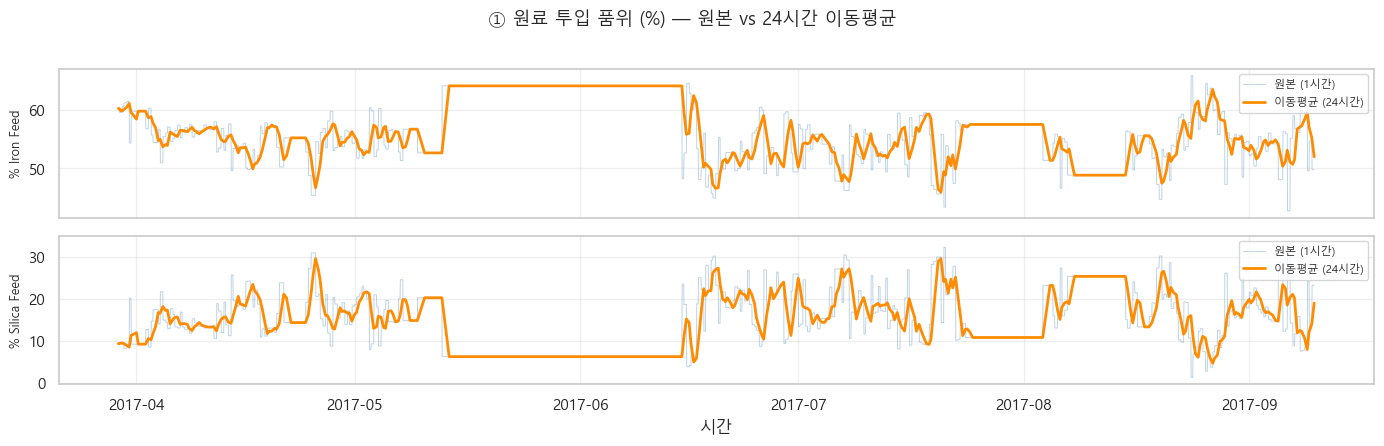

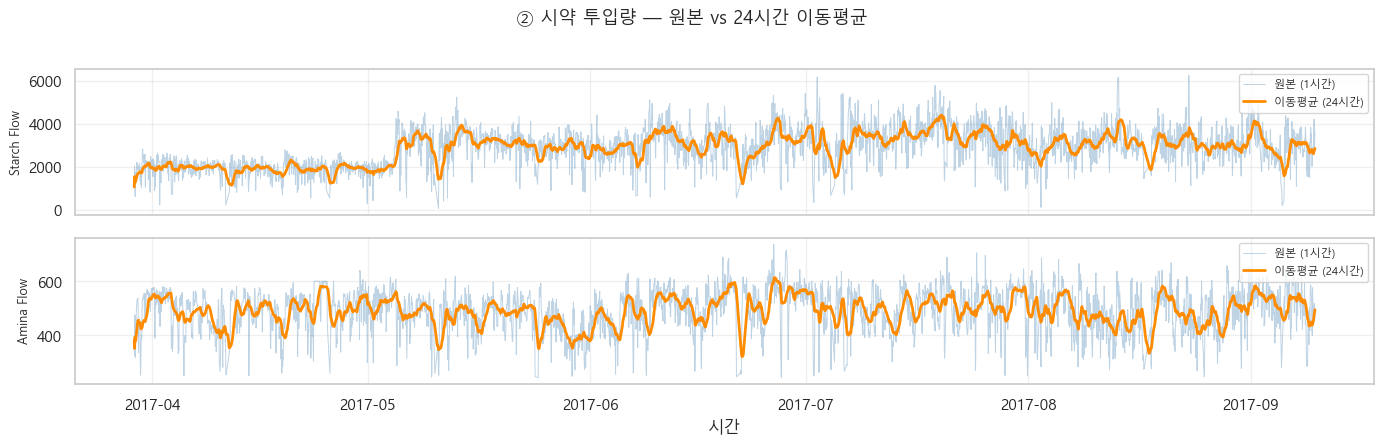

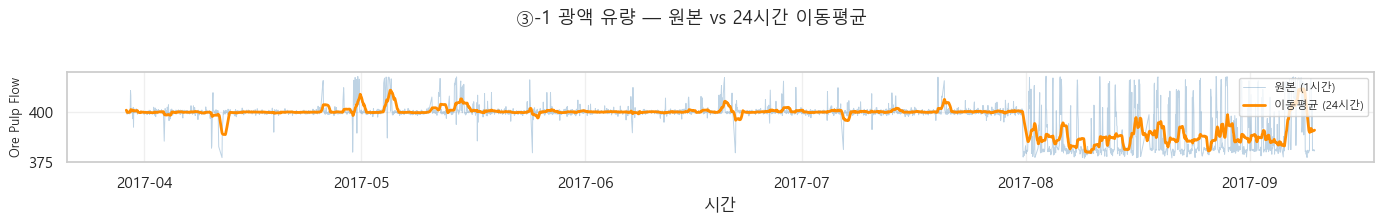

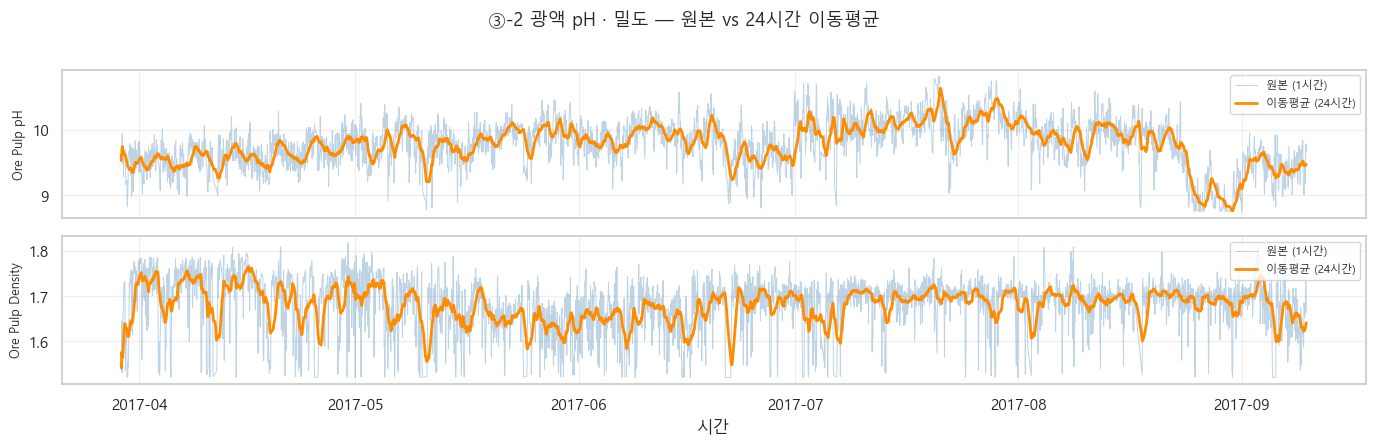

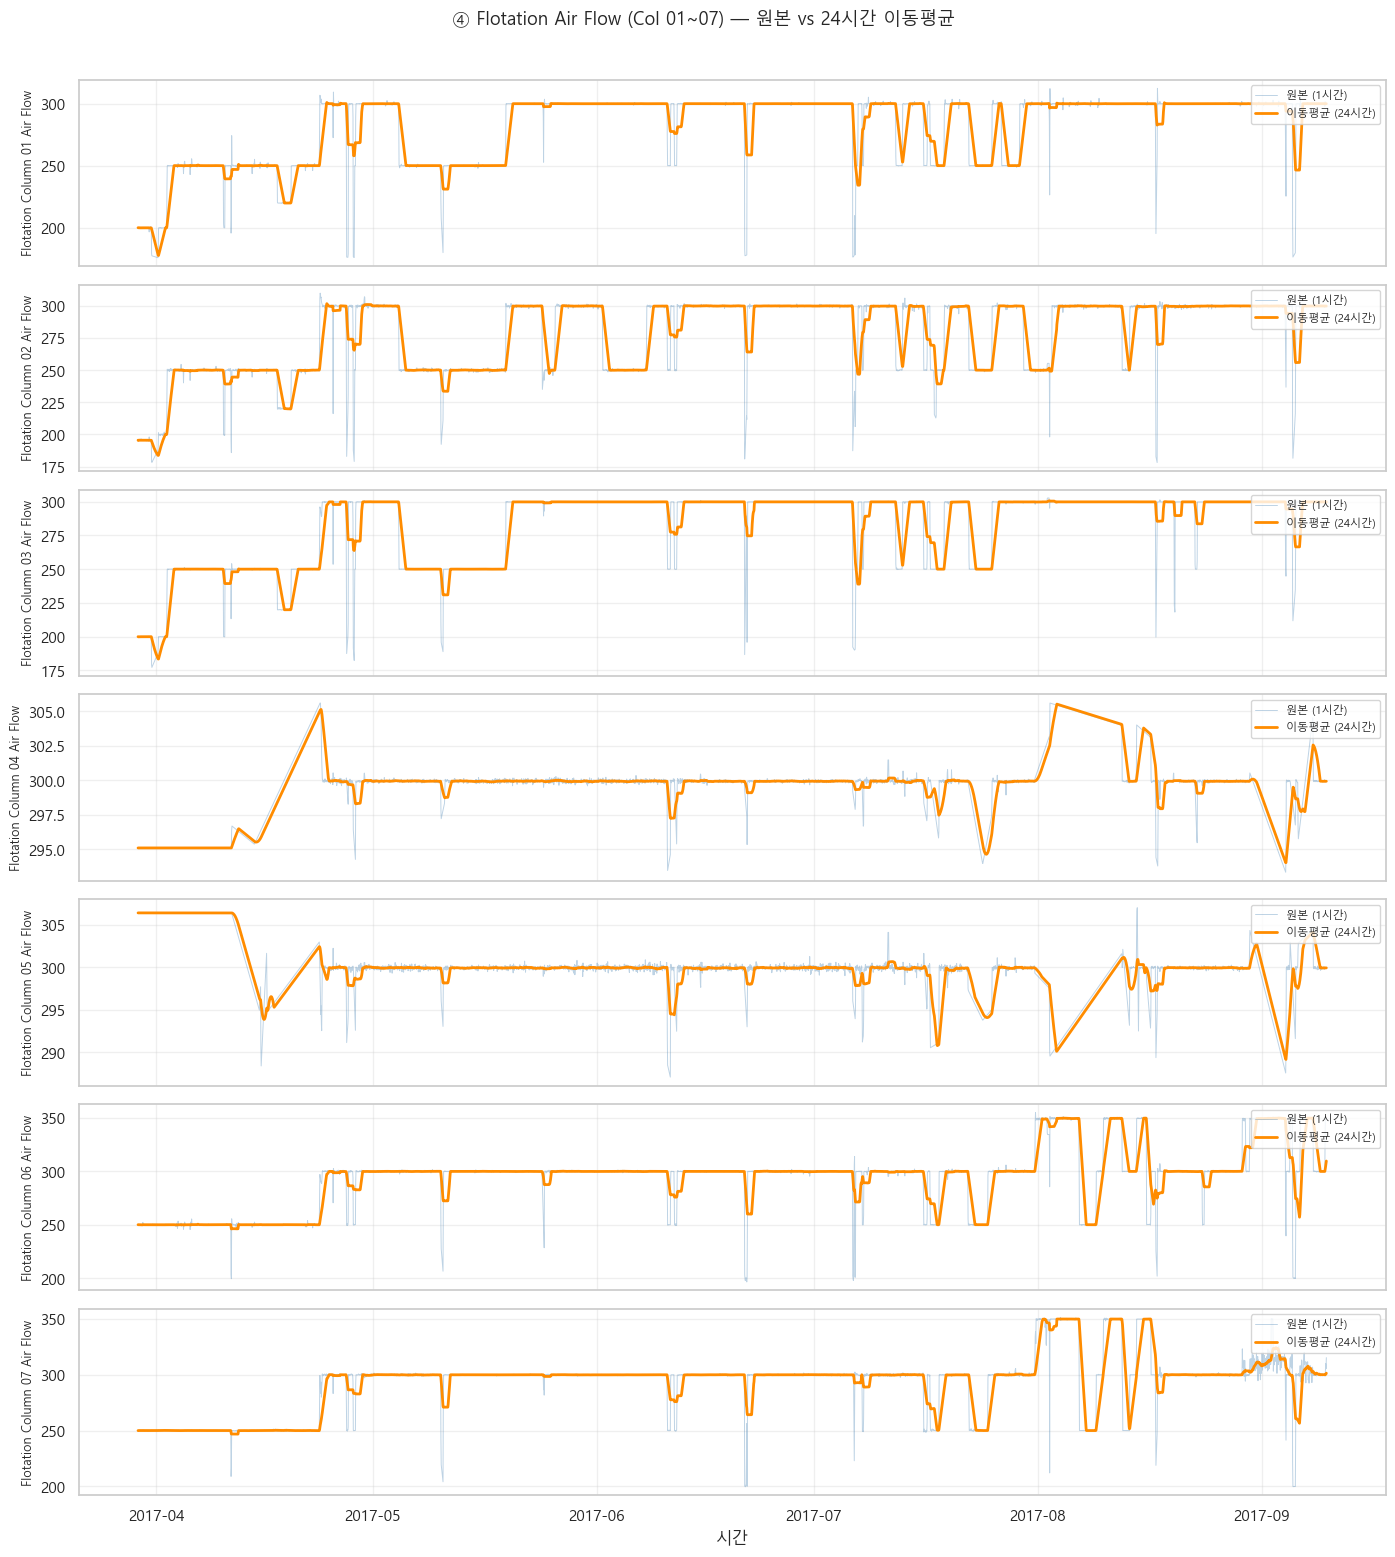

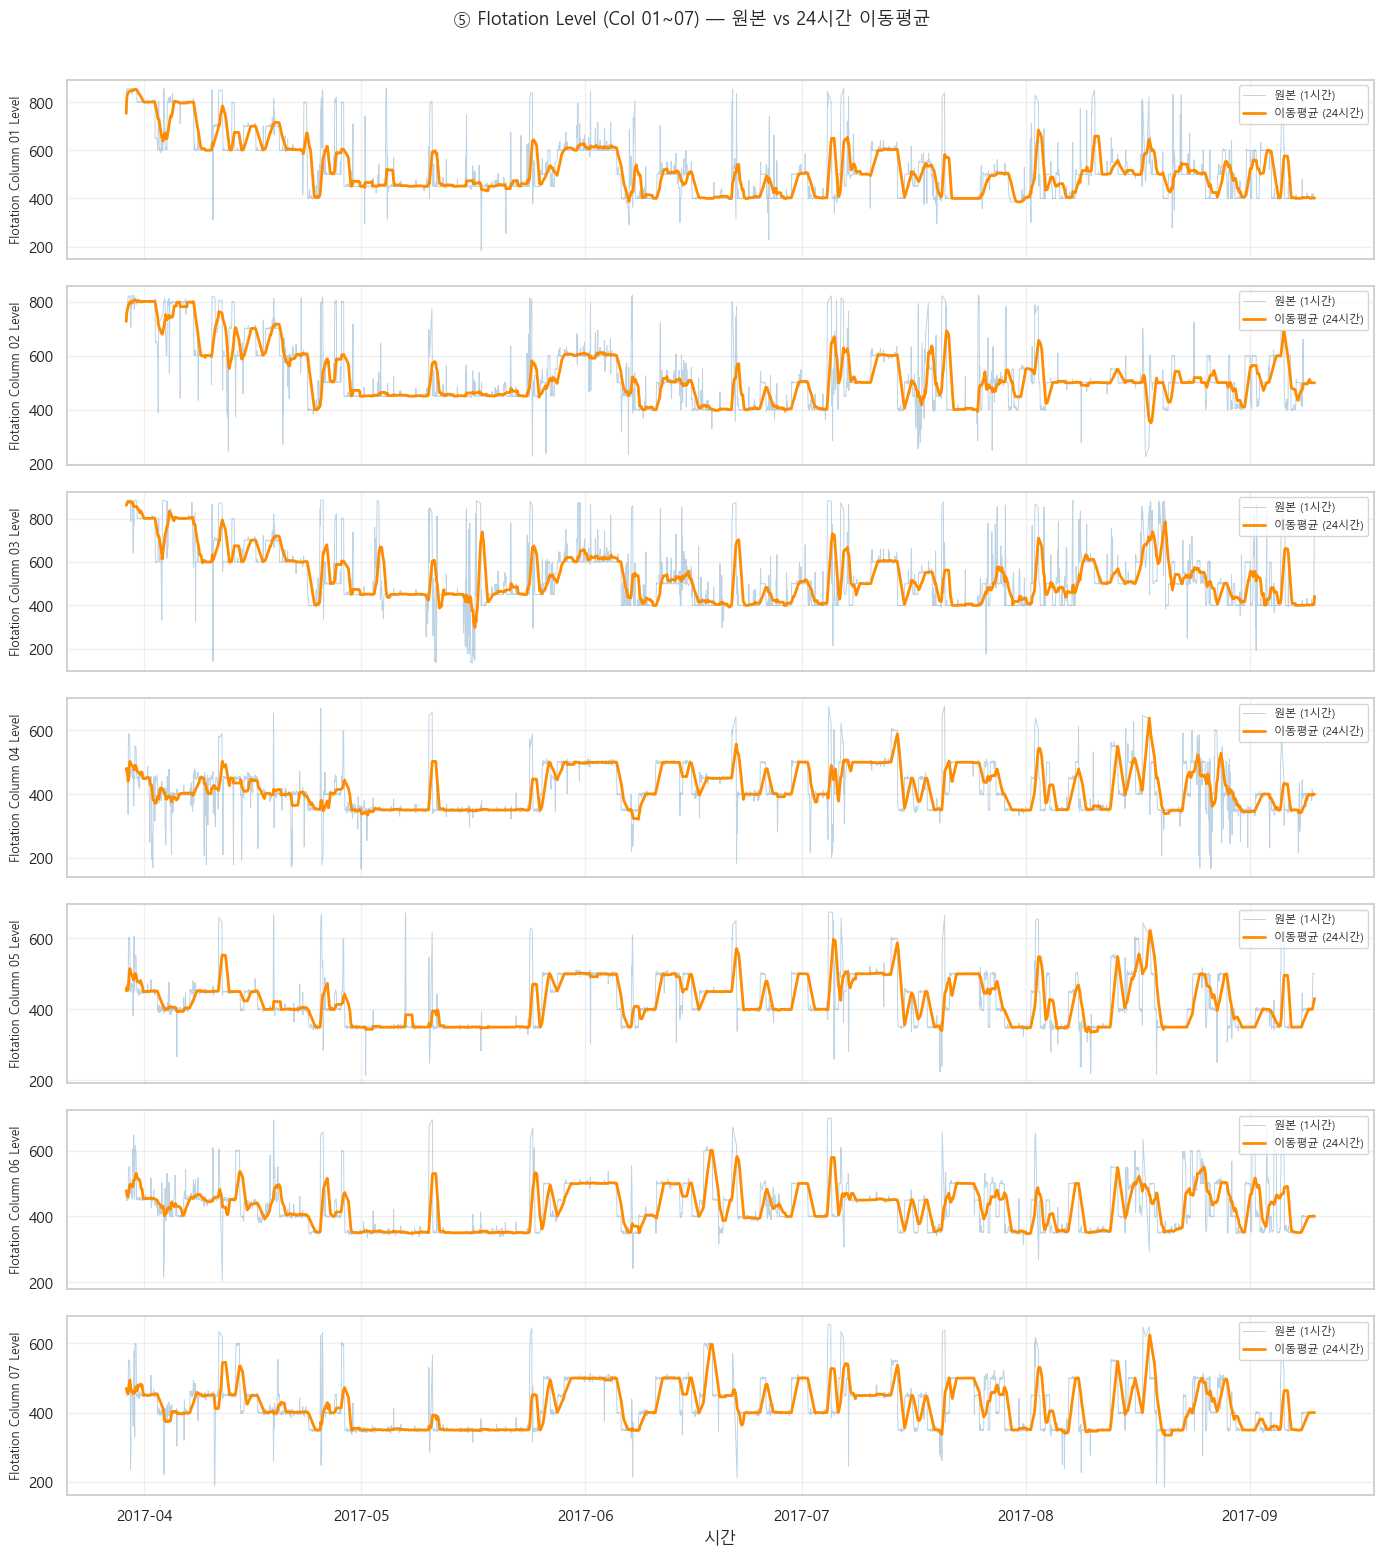

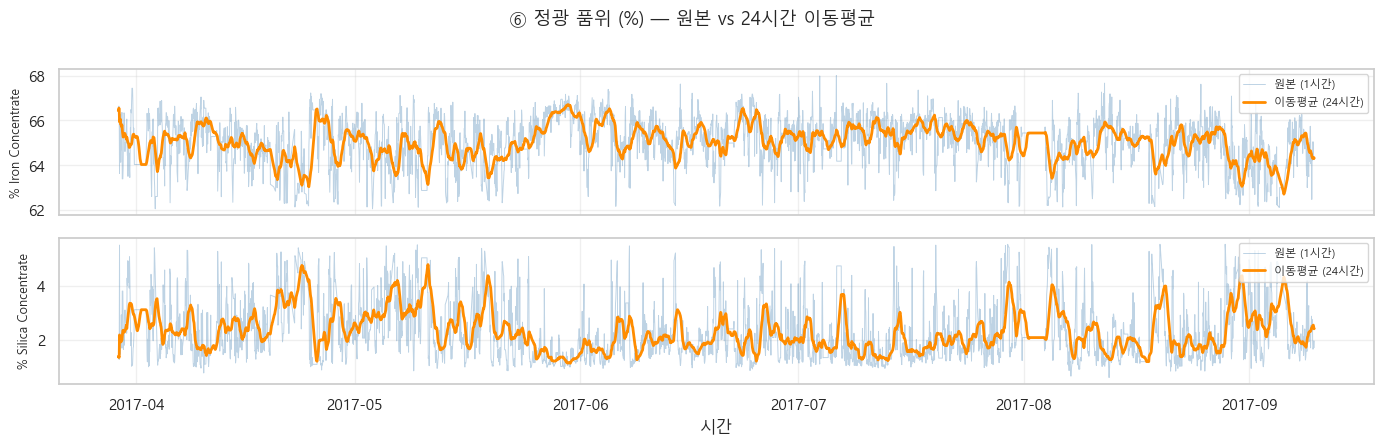

In [15]:
# ============================================================
# 시계열 Line Plot + 이동평균 추세선 (변수별)
# ============================================================

df_ts = df_reg.set_index("date").sort_index()

# 이동평균 윈도우 (1시간 간격 데이터 → 24 = 1일)
ROLLING_WINDOW = 24

plot_groups = {
    "① 원료 투입 품위 (%)": [
        "% Iron Feed",
        "% Silica Feed",
    ],
    "② 시약 투입량": [
        "Starch Flow",
        "Amina Flow",
    ],
    "③-1 광액 유량": [
        "Ore Pulp Flow",
    ],
    "③-2 광액 pH · 밀도": [
        "Ore Pulp pH",
        "Ore Pulp Density",
    ],
    "④ Flotation Air Flow (Col 01~07)": [
        f"Flotation Column {i:02d} Air Flow" for i in range(1, 8)
    ],
    "⑤ Flotation Level (Col 01~07)": [
        f"Flotation Column {i:02d} Level" for i in range(1, 8)
    ],
    "⑥ 정광 품위 (%)": [
        "% Iron Concentrate",
        "% Silica Concentrate",
    ],
}


def plot_timeseries_with_rolling(
    df,
    groups,
    window=24,
    figsize_per_row=2.2,
    raw_alpha=0.35,
    raw_lw=0.7,
    ma_lw=2.0,
):
    """
    그룹별로 변수마다 subplot을 만들고
    각 subplot에 원본(연한 선) + 이동평균(진한 선)을 함께 표시
    """
    for group_title, cols in groups.items():
        cols = [c for c in cols if c in df.columns]
        if not cols:
            print(f"[건너뜀] {group_title}: 컬럼 없음")
            continue

        n = len(cols)
        fig, axes = plt.subplots(
            n, 1,
            figsize=(14, figsize_per_row * n),
            sharex=True,
            squeeze=False,
        )
        axes = axes.flatten()

        for ax, col in zip(axes, cols):
            series = df[col]
            rolling_ma = series.rolling(window=window, min_periods=1).mean()

            # 원본 (단기 노이즈)
            ax.plot(
                series.index, series.values,
                color="steelblue", alpha=raw_alpha, linewidth=raw_lw,
                label="원본 (1시간)",
            )
            # 이동평균 (추세)
            ax.plot(
                series.index, rolling_ma.values,
                color="darkorange", linewidth=ma_lw,
                label=f"이동평균 ({window}시간)",
            )

            ax.set_ylabel(col, fontsize=9)
            ax.grid(True, alpha=0.3)
            ax.legend(loc="upper right", fontsize=8)

        axes[-1].set_xlabel("시간")
        fig.suptitle(
            f"{group_title} — 원본 vs {window}시간 이동평균",
            fontsize=13, y=1.01,
        )
        plt.tight_layout()
        plt.show()


# 실행
plot_timeseries_with_rolling(df_ts, plot_groups, window=ROLLING_WINDOW)

Air Flow 변수는 시간에 따른 연속적 추세보다 장비 설정값에 가까운 수준이며, 컬럼 간 동시 변화가 관찰되어 다중공선성이 예상된다. Ore Pulp Flow는 2017년 8월 이후 변동성이 크게 증가하여 운전 구간이 달라진 것으로 해석하였다. 따라서 본 분석에서는 date를 직접 입력하지 않되, 검증 시 무작위 분할과 시간 순 분할을 비교하고, 필요 시 8월 이전 구간에 대한 추가 분석을 수행하였다.

**[과제]** 써니는 변수들 간에 강하게 얽혀 있는 관계(다중공선성 후보)가 있는지 한눈에 살펴보고 싶습니다. 전체 변수 간 관계를 효율적으로 볼 수 있는 방법을 AI와 상의해서 시각화해 보세요.

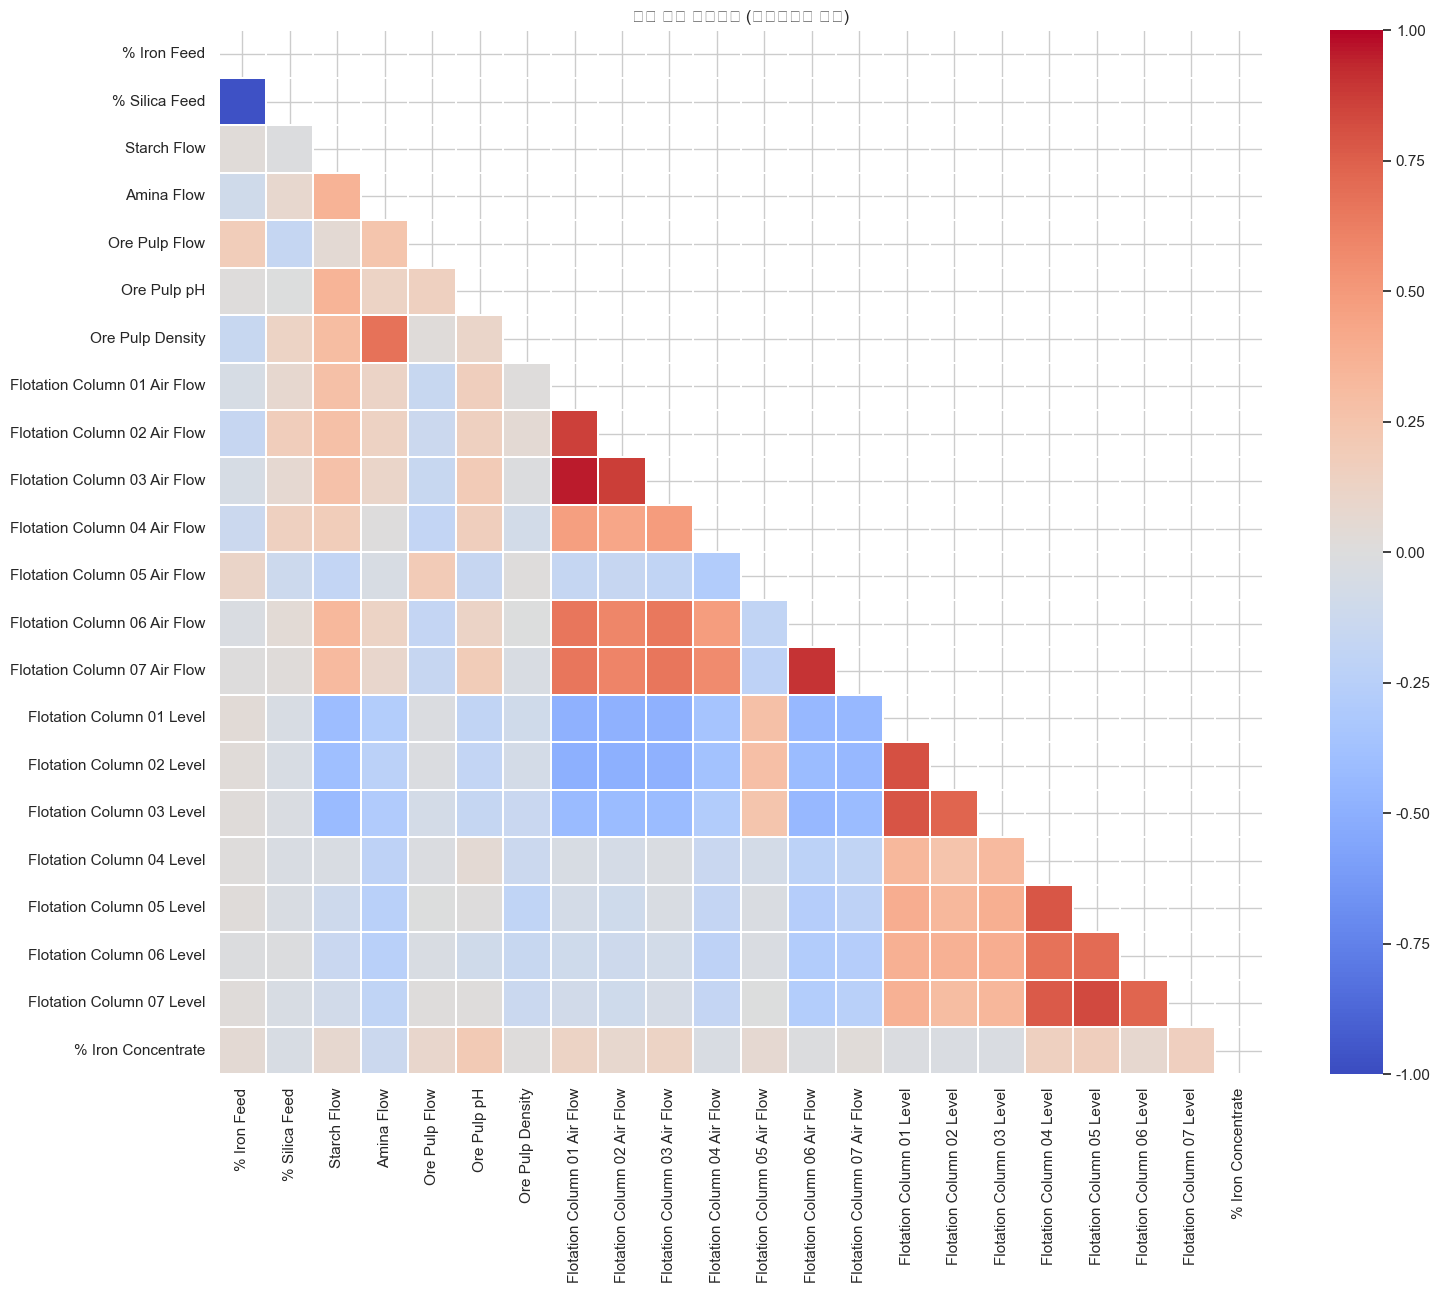

|상관계수| >= 0.8 인 변수 쌍: 7개


,변수1,변수2,상관계수,절댓값
0,% Iron Feed,% Silica Feed,-0.9720,0.9720
1,Flotation Column 01 Air Flow,Flotation Column 03 Air Flow,0.9580,0.9580
2,Flotation Column 06 Air Flow,Flotation Column 07 Air Flow,0.9030,0.9030
3,Flotation Column 02 Air Flow,Flotation Column 03 Air Flow,0.8750,0.8750
4,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,0.8620,0.8620
5,Flotation Column 05 Level,Flotation Column 07 Level,0.8300,0.8300
6,Flotation Column 01 Level,Flotation Column 02 Level,0.8070,0.8070


In [22]:
target = "% Silica Concentrate"

# 모델링 입력 후보 (date 제외, 타겟 제외)
# % Iron Concentrate는 누수 가능성 있어 EDA용/제외용 둘 다 준비
feature_cols = [
    c for c in df_reg.columns
    if c not in ["date", target]
]

X_eda = df_reg[feature_cols].select_dtypes(include="number")
corr = X_eda.corr()

# ----- 1) 전체 히트맵 -----
plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))   # 위쪽 삼각형만 (중복 제거)
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    annot=False,          # 변수 많으면 False / 적으면 True
    square=True,
    linewidths=0.3,
)
plt.title("입력 변수 상관행렬 (다중공선성 탐색)")
plt.tight_layout()
plt.show()

# ----- 2) 고상관 쌍 테이블 (|r| >= 0.8) -----
threshold = 0.8

pairs = []
cols = corr.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        if abs(r) >= threshold:
            pairs.append({
                "변수1": cols[i],
                "변수2": cols[j],
                "상관계수": round(r, 3),
                "절댓값": round(abs(r), 3),
            })

high_corr_df = (
    pd.DataFrame(pairs)
    .sort_values("절댓값", ascending=False)
    .reset_index(drop=True)
)

print(f"|상관계수| >= {threshold} 인 변수 쌍: {len(high_corr_df)}개")
display(high_corr_df)

---
## A-2) 데이터 전처리

### A-2-1) 불필요한 변수 제거 및 결측치 확인

**[과제]** 써니는 모델링 전에 입력변수들을 점검해 보기로 했습니다. AI와 함께 각 변수의 의미를 확인하고, date와 같이 사용 여부를 고민해야 하는 변수나 데이터 누수를 유발할 수 있는 변수가 없는지 검토하고 제거해보세요.

In [23]:
# ============================================================
# 분석용 데이터프레임 — % Iron Feed 제외
# (원본 df_reg는 유지)
# ============================================================

IRON_FEED_COL = "% Iron Feed"

# 제외할 컬럼이 실제로 있는지 확인
if IRON_FEED_COL not in df_reg.columns:
    raise KeyError(f"'{IRON_FEED_COL}' 컬럼이 df_reg에 없습니다.")

# 분석용 복사본 (Iron Feed만 제외)
df_reg_analysis = df_reg.drop(columns=[IRON_FEED_COL])

print(f"원본 shape      : {df_reg.shape}")
print(f"분석용 shape    : {df_reg_analysis.shape}")
print(f"제외된 컬럼     : {IRON_FEED_COL}")
print(f"남은 컬럼 수    : {len(df_reg_analysis.columns)}")
print("\n[분석용 컬럼 목록]")
print(df_reg_analysis.columns.tolist())

원본 shape      : (3948, 24)
분석용 shape    : (3948, 23)
제외된 컬럼     : % Iron Feed
남은 컬럼 수    : 23

[분석용 컬럼 목록]
['date', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level', '% Iron Concentrate', '% Silica Concentrate']


### A-2-2) 입출력 변수 분할 및 데이터 분할

**[과제]** 써니는 `% Silica Concentrate`를 예측하기 위해 입력변수와 타겟 변수를 분리하고자 합니다. 또한 데이터가 시간에 따라 수집되었다는 점을 고려하여 어떤 방식으로 학습 데이터와 테스트 데이터를 나누는 것이 적절할지 AI와 상의한 후, 데이터를 분할해 보세요.

In [24]:
# ============================================================
# 시계열 Train / Test — 2가지 세트
# ============================================================

target = "% Silica Concentrate"
VOLATILE_START = pd.Timestamp("2017-08-01")   # 광액 유량 변동 급증 구간
TEST_RATIO = 0.2                              # Set A용 (안정 구간 내 비율)

# 분석용 df 사용 (Iron Feed 제외된 df_reg_analysis)
# 없으면 df_reg.drop(columns=["% Iron Feed"]) 로 대체
df = df_reg_analysis.sort_values("date").reset_index(drop=True)

def temporal_split(df, test_ratio=0.2):
    """시간순 정렬 후 앞쪽 train, 뒤쪽 test"""
    n = len(df)
    split_idx = int(n * (1 - test_ratio))
    train = df.iloc[:split_idx].copy()
    test = df.iloc[split_idx:].copy()
    return train, test


def regime_split(df, volatile_start):
    """변동 구간 이전 = train, 이후 = test"""
    train = df[df["date"] < volatile_start].copy()
    test = df[df["date"] >= volatile_start].copy()
    return train, test


def summarize_split(name, train, test, flow_col="Ore Pulp Flow"):
    print(f"\n{'='*55}")
    print(f"[{name}]")
    print(f"Train: {len(train):4d}행 | {train['date'].min()} ~ {train['date'].max()}")
    print(f"Test : {len(test):4d}행 | {test['date'].min()} ~ {test['date'].max()}")
    print(f"Train {flow_col} — mean: {train[flow_col].mean():.2f}, std: {train[flow_col].std():.2f}")
    print(f"Test  {flow_col} — mean: {test[flow_col].mean():.2f}, std: {test[flow_col].std():.2f}")
    print(f"Train target std: {train[target].std():.4f}")
    print(f"Test  target std: {test[target].std():.4f}")


# ----- Set A: 안정 구간만 (8월 이전) + 시간순 80/20 -----
df_stable = df[df["date"] < VOLATILE_START].copy()

train_a, test_a = temporal_split(df_stable, test_ratio=TEST_RATIO)

# X, y 분리
X_train_a = train_a.drop(columns=["date", target])
y_train_a = train_a[target]
X_test_a  = test_a.drop(columns=["date", target])
y_test_a  = test_a[target]

summarize_split("Set A — 안정 구간 + 시간순 분할", train_a, test_a)


# ----- Set B: 변동 구간을 Test에 포함 (7월까지 Train / 8월~ Test) -----
train_b, test_b = regime_split(df, VOLATILE_START)

X_train_b = train_b.drop(columns=["date", target])
y_train_b = train_b[target]
X_test_b  = test_b.drop(columns=["date", target])
y_test_b  = test_b[target]

summarize_split("Set B — 변동 구간 반영 (Pre-Aug Train / Aug+ Test)", train_b, test_b)


[Set A — 안정 구간 + 시간순 분할]
Train: 2390행 | 2017-03-29 12:00:00 ~ 2017-07-07 01:00:00
Test :  598행 | 2017-07-07 02:00:00 ~ 2017-07-31 23:00:00
Train Ore Pulp Flow — mean: 400.35, std: 3.65
Test  Ore Pulp Flow — mean: 400.13, std: 3.51
Train target std: 1.1299
Test  target std: 0.9994

[Set B — 변동 구간 반영 (Pre-Aug Train / Aug+ Test)]
Train: 2988행 | 2017-03-29 12:00:00 ~ 2017-07-31 23:00:00
Test :  960행 | 2017-08-01 00:00:00 ~ 2017-09-09 23:00:00
Train Ore Pulp Flow — mean: 400.30, std: 3.62
Test  Ore Pulp Flow — mean: 388.66, std: 12.38
Train target std: 1.1153
Test  target std: 1.1354


### A-2-3) 변수 스케일링 및 인코딩

**[과제]** 써니는 변수마다 값의 범위와 단위가 다를 경우 스케일링이 필요하고 범주형 변수의 경우 숫자로 바꿔주는 인코딩이 필요할 수 있다는 것을 배웠습니다. AI와 함께 적절한 스케일링 및 인코딩 기법을 선택하여 적용해 보세요.

In [25]:
from sklearn.preprocessing import StandardScaler

# 선형 계열 모델용 (Set A / Set B 각각 train에 fit)
scaler_a = StandardScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a)
X_test_a_scaled  = scaler_a.transform(X_test_a)

scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_test_b_scaled  = scaler_b.transform(X_test_b)

# 의사결정나무 → 스케일링 없이 원본 X_train_b, X_test_b 사용

---
## A-3) 모델링

### A-3-1) 다중선형회귀

**[과제]** 써니는 다중선형회귀 모델을 학습시키고, 회귀 계수를 통해 어떤 공정 변수가 실리카 비율에 큰 영향을 주는지 확인하려고 합니다. 모델을 학습하고 회귀 계수를 변수명과 함께 정리해 보세요.

In [26]:
# ============================================================
# 다중선형회귀 + 회귀계수 정리 (Set A / Set B)
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

target = "% Silica Concentrate"

# 모델링에서 제외할 컬럼 (누수·비입력)
DROP_FOR_MODEL = ["date", target, "% Iron Concentrate"]


def prepare_xy(train_df, test_df, drop_cols=DROP_FOR_MODEL):
    """X, y 분리 + date/target/누수 변수 제거"""
    X_train = train_df.drop(columns=drop_cols, errors="ignore")
    X_test  = test_df.drop(columns=drop_cols, errors="ignore")
    y_train = train_df[target]
    y_test  = test_df[target]
    return X_train, X_test, y_train, y_test


def fit_linear_and_summarize(X_train, X_test, y_train, y_test, set_name, use_scaler=True):
    """
  다중선형회귀 학습 후 회귀계수·성능 정리
  use_scaler=True  → StandardScaler (계수 크기 비교에 유리)
  use_scaler=False → 원본 스케일 (단위 해석)
    """
    feature_names = X_train.columns.tolist()

    if use_scaler:
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_train)
        X_te = scaler.transform(X_test)
    else:
        scaler = None
        X_tr = X_train.values
        X_te = X_test.values

    model = LinearRegression()
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    # ----- 회귀계수 테이블 -----
    coef_df = pd.DataFrame({
        "변수": feature_names,
        "회귀계수": model.coef_,
        "절댓값": np.abs(model.coef_),
    }).sort_values("절댓값", ascending=False).reset_index(drop=True)

    # ----- 성능 -----
    metrics = {
        "세트": set_name,
        "Train R2": r2_score(y_train, model.predict(X_tr)),
        "Test R2": r2_score(y_test, y_pred),
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "절편": model.intercept_,
    }

    print(f"\n{'='*60}")
    print(f"[{set_name}] 다중선형회귀 결과")
    print(f"{'='*60}")
    print(f"절편 (intercept): {model.intercept_:.4f}")
    print(f"Train R2: {metrics['Train R2']:.4f} | Test R2: {metrics['Test R2']:.4f}")
    print(f"Test MAE: {metrics['Test MAE']:.4f} | Test RMSE: {metrics['Test RMSE']:.4f}")
    print(f"\n--- 회귀계수 (|계수| 내림차순) ---")
    display(coef_df)

    return model, scaler, coef_df, metrics


# ----- Set A / Set B 준비 (이미 만들었다면 이 블록은 생략) -----
# train_a, test_a, train_b, test_b 가 있다고 가정

X_train_a, X_test_a, y_train_a, y_test_a = prepare_xy(train_a, test_a)
X_train_b, X_test_b, y_train_b, y_test_b = prepare_xy(train_b, test_b)

# ----- 모델링 + 계수 정리 -----
model_a, scaler_a, coef_a, metrics_a = fit_linear_and_summarize(
    X_train_a, X_test_a, y_train_a, y_test_a,
    set_name="Set A (안정 구간)",
    use_scaler=True,
)

model_b, scaler_b, coef_b, metrics_b = fit_linear_and_summarize(
    X_train_b, X_test_b, y_train_b, y_test_b,
    set_name="Set B (변동 구간 Test)",
    use_scaler=True,
)

# ----- 두 세트 성능 한눈에 비교 -----
pd.DataFrame([metrics_a, metrics_b])


[Set A (안정 구간)] 다중선형회귀 결과
절편 (intercept): 2.3910
Train R2: 0.2287 | Test R2: -0.0893
Test MAE: 0.8006 | Test RMSE: 1.0422

--- 회귀계수 (|계수| 내림차순) ---


,변수,회귀계수,절댓값
0,Flotation Column 03 Air Flow,-0.3309,0.3309
1,Amina Flow,0.3134,0.3134
2,Flotation Column 04 Air Flow,0.2670,0.2670
3,Flotation Column 01 Air Flow,-0.1969,0.1969
4,Flotation Column 06 Air Flow,-0.1934,0.1934
5,Flotation Column 07 Air Flow,0.1843,0.1843
6,Flotation Column 02 Level,-0.1614,0.1614
7,Flotation Column 05 Level,-0.1608,0.1608
8,Ore Pulp Density,-0.1590,0.1590
9,Starch Flow,-0.1135,0.1135



[Set B (변동 구간 Test)] 다중선형회귀 결과
절편 (intercept): 2.3152
Train R2: 0.2005 | Test R2: -0.0436
Test MAE: 0.9075 | Test RMSE: 1.1593

--- 회귀계수 (|계수| 내림차순) ---


,변수,회귀계수,절댓값
0,Amina Flow,0.3161,0.3161
1,Flotation Column 06 Air Flow,-0.2650,0.2650
2,Flotation Column 07 Air Flow,0.2482,0.2482
3,Flotation Column 01 Air Flow,-0.2465,0.2465
4,Flotation Column 04 Air Flow,0.2374,0.2374
5,Flotation Column 03 Air Flow,-0.1947,0.1947
6,Flotation Column 05 Level,-0.1810,0.1810
7,Ore Pulp Density,-0.1569,0.1569
8,Starch Flow,-0.0976,0.0976
9,Flotation Column 06 Level,0.0588,0.0588


,세트,Train R2,Test R2,Test MAE,Test RMSE,절편
0,Set A (안정 구간),0.2287,-0.0893,0.8006,1.0422,2.3910
1,Set B (변동 구간 Test),0.2005,-0.0436,0.9075,1.1593,2.3152


### A-3-2) Ridge/Lasso 회귀

**[과제]** 써니는 A-1에서 확인한 다중공선성 문제가 정규화(Regularization) 기법을 통해 완화될 수 있는지 확인해보려고 합니다. Ridge 회귀와 Lasso 회귀 모델을 학습하고 각 모델의 예측 성능과 계수 변화를 함께 분석하여, 해당 데이터에 가장 적절한 모델을 선택하세요.

In [27]:
# ============================================================
# Ridge / Lasso 회귀 — 데이터셋별 평가 (다중공선성 완화 확인)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

target = "% Silica Concentrate"
DROP_FOR_MODEL = ["date", target, "% Iron Concentrate"]

# alpha 후보 (로그 스케일)
ALPHAS = np.logspace(-2, 3, 20)   # 0.01 ~ 1000


def prepare_xy(train_df, test_df):
    X_train = train_df.drop(columns=DROP_FOR_MODEL, errors="ignore")
    X_test  = test_df.drop(columns=DROP_FOR_MODEL, errors="ignore")
    y_train = train_df[target]
    y_test  = test_df[target]
    return X_train, X_test, y_train, y_test


def eval_regression(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


def get_coef_table(model, feature_names, model_name):
    """Pipeline 내 Ridge/Lasso/Linear 계수 추출"""
    reg = model.named_steps["model"]
    coef = reg.coef_
    return pd.DataFrame({
        "모델": model_name,
        "변수": feature_names,
        "회귀계수": coef,
        "절댓값": np.abs(coef),
    }).sort_values("절댓값", ascending=False)


def fit_and_evaluate_set(set_name, X_train, X_test, y_train, y_test, tune_alpha=True):
    """
    한 세트(Set A/B)에 대해 Linear / Ridge / Lasso 학습·평가
    """
    feature_names = X_train.columns.tolist()
    results = []
    coef_tables = []
    fitted_models = {}

    # ----- 1) 다중선형회귀 (baseline) -----
    pipe_lr = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])
    pipe_lr.fit(X_train, y_train)
    fitted_models["Linear"] = pipe_lr

    for split_name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        m = eval_regression(y, pipe_lr.predict(X))
        results.append({"세트": set_name, "모델": "Linear", "구분": split_name, **m})

    coef_tables.append(get_coef_table(pipe_lr, feature_names, "Linear"))

    # ----- 2) Ridge / Lasso -----
    for model_name, ModelClass in [("Ridge", Ridge), ("Lasso", Lasso)]:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", ModelClass(max_iter=10000)),
        ])

        if tune_alpha:
            # train 내부 TimeSeriesSplit으로 alpha 선택 (test 누수 방지)
            tscv = TimeSeriesSplit(n_splits=5)
            grid = GridSearchCV(
                pipe,
                param_grid={"model__alpha": ALPHAS},
                cv=tscv,
                scoring="neg_mean_absolute_error",
                n_jobs=-1,
            )
            grid.fit(X_train, y_train)
            best_model = grid.best_estimator_
            best_alpha = grid.best_params_["model__alpha"]
        else:
            best_model = Pipeline([
                ("scaler", StandardScaler()),
                ("model", ModelClass(alpha=1.0, max_iter=10000)),
            ])
            best_model.fit(X_train, y_train)
            best_alpha = 1.0

        fitted_models[model_name] = best_model

        for split_name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
            m = eval_regression(y, best_model.predict(X))
            results.append({
                "세트": set_name,
                "모델": model_name,
                "구분": split_name,
                "best_alpha": best_alpha,
                **m,
            })

        coef_tables.append(get_coef_table(best_model, feature_names, model_name))

    metrics_df = pd.DataFrame(results)
    coef_df = pd.concat(coef_tables, ignore_index=True)

    return metrics_df, coef_df, fitted_models


# ============================================================
# 실행 — Set A / Set B
# (train_a, test_a, train_b, test_b 가 이미 있다고 가정)
# ============================================================

X_train_a, X_test_a, y_train_a, y_test_a = prepare_xy(train_a, test_a)
X_train_b, X_test_b, y_train_b, y_test_b = prepare_xy(train_b, test_b)

metrics_a, coef_a, models_a = fit_and_evaluate_set(
    "Set A (안정)", X_train_a, X_test_a, y_train_a, y_test_a
)
metrics_b, coef_b, models_b = fit_and_evaluate_set(
    "Set B (변동 Test)", X_train_b, X_test_b, y_train_b, y_test_b
)

metrics_all = pd.concat([metrics_a, metrics_b], ignore_index=True)

# ----- 성능 비교표 (Test만) -----
print("=== Test 성능 비교 ===")
display(
    metrics_all[metrics_all["구분"] == "Test"]
    .pivot_table(
        index=["세트", "모델"],
        values=["R2", "MAE", "RMSE", "best_alpha"],
        aggfunc="first",
    )
    .round(4)
)

print("\n=== 전체 Train/Test ===")
display(metrics_all.round(4))

# ----- 계수 비교 (Set B 예시 — 다중공선성 완화 확인) -----
print("\n=== Set B 회귀계수 비교 (|계수| 내림차순) ===")
for m in ["Linear", "Ridge", "Lasso"]:
    print(f"\n--- {m} ---")
    display(
        coef_b[coef_b["모델"] == m][["변수", "회귀계수", "절댓값"]]
        .reset_index(drop=True)
    )

# ----- Lasso가 0으로 만든 변수 (변수 선택 효과) -----
lasso_coef_b = coef_b[coef_b["모델"] == "Lasso"]
zeroed = lasso_coef_b[lasso_coef_b["회귀계수"].abs() < 1e-6]["변수"].tolist()
print(f"\n[Set B] Lasso에서 제거된 변수(계수≈0): {zeroed if zeroed else '없음'}")

=== Test 성능 비교 ===


MAE      R2   RMSE  best_alpha
세트              모델                                      
Set A (안정)      Lasso  0.8229 -0.0563 1.0263      0.0336
                Linear 0.8006 -0.0893 1.0422         NaN
                Ridge  0.8048 -0.0703 1.0331    162.3777
Set B (변동 Test) Lasso  0.8645  0.0710 1.0938      0.0336
                Linear 0.9075 -0.0436 1.1593         NaN
                Ridge  0.8589  0.0784 1.0894  1,000.0000


=== 전체 Train/Test ===


,세트,모델,구분,R2,MAE,RMSE,best_alpha
0,Set A (안정),Linear,Train,0.2287,0.7789,0.9921,NaN
1,Set A (안정),Linear,Test,-0.0893,0.8006,1.0422,NaN
2,Set A (안정),Ridge,Train,0.2245,0.7853,0.9949,162.3777
3,Set A (안정),Ridge,Test,-0.0703,0.8048,1.0331,162.3777
4,Set A (안정),Lasso,Train,0.2068,0.8007,1.0062,0.0336
5,Set A (안정),Lasso,Test,-0.0563,0.8229,1.0263,0.0336
6,Set B (변동 Test),Linear,Train,0.2005,0.7797,0.9970,NaN
7,Set B (변동 Test),Linear,Test,-0.0436,0.9075,1.1593,NaN
8,Set B (변동 Test),Ridge,Train,0.1788,0.7974,1.0105,"1,000.0000"
9,Set B (변동 Test),Ridge,Test,0.0784,0.8589,1.0894,"1,000.0000"



=== Set B 회귀계수 비교 (|계수| 내림차순) ===

--- Linear ---


...


--- Ridge ---


,변수,회귀계수,절댓값
0,Flotation Column 04 Air Flow,0.1509,0.1509
1,Amina Flow,0.1497,0.1497
2,Flotation Column 01 Air Flow,-0.1390,0.1390
3,Flotation Column 03 Air Flow,-0.1132,0.1132
4,Flotation Column 05 Level,-0.1016,0.1016
5,Starch Flow,-0.0632,0.0632
6,Ore Pulp pH,-0.0562,0.0562
7,Flotation Column 02 Air Flow,-0.0560,0.0560
8,% Silica Feed,0.0515,0.0515
9,Ore Pulp Density,-0.0477,0.0477



--- Lasso ---


,변수,회귀계수,절댓값
0,Flotation Column 01 Air Flow,-0.2621,0.2621
1,Flotation Column 04 Air Flow,0.1802,0.1802
2,Amina Flow,0.1587,0.1587
3,Flotation Column 05 Level,-0.1478,0.1478
4,Flotation Column 03 Air Flow,-0.0901,0.0901
5,Starch Flow,-0.0739,0.0739
6,Ore Pulp pH,-0.0526,0.0526
7,Ore Pulp Density,-0.0269,0.0269
8,% Silica Feed,0.0252,0.0252
9,Flotation Column 07 Level,-0.0034,0.0034



[Set B] Lasso에서 제거된 변수(계수≈0): ['Flotation Column 02 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Ore Pulp Flow', 'Flotation Column 06 Level', 'Flotation Column 05 Air Flow']


### A-3-3) 의사결정나무 회귀

**[과제]** 써니는 공정 변수와 % Silica Concentrate 사이에 선형 회귀만으로는 설명하기 어려운 비선형 관계가 존재할 수 있다고 생각했습니다. AI와 함께 회귀 나무 모델을 구축하고 학습된 트리를 시각화하여 주요 분할 기준과 의사결정 과정을 해석해 보세요.

In [28]:
# ============================================================
# Ridge / Lasso 회귀 — 데이터셋별 평가 (다중공선성 완화 확인)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

target = "% Silica Concentrate"
DROP_FOR_MODEL = ["date", target, "% Iron Concentrate"]

# alpha 후보 (로그 스케일)
ALPHAS = np.logspace(-2, 3, 20)   # 0.01 ~ 1000


def prepare_xy(train_df, test_df):
    X_train = train_df.drop(columns=DROP_FOR_MODEL, errors="ignore")
    X_test  = test_df.drop(columns=DROP_FOR_MODEL, errors="ignore")
    y_train = train_df[target]
    y_test  = test_df[target]
    return X_train, X_test, y_train, y_test


def eval_regression(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


def get_coef_table(model, feature_names, model_name):
    """Pipeline 내 Ridge/Lasso/Linear 계수 추출"""
    reg = model.named_steps["model"]
    coef = reg.coef_
    return pd.DataFrame({
        "모델": model_name,
        "변수": feature_names,
        "회귀계수": coef,
        "절댓값": np.abs(coef),
    }).sort_values("절댓값", ascending=False)


def fit_and_evaluate_set(set_name, X_train, X_test, y_train, y_test, tune_alpha=True):
    """
    한 세트(Set A/B)에 대해 Linear / Ridge / Lasso 학습·평가
    """
    feature_names = X_train.columns.tolist()
    results = []
    coef_tables = []
    fitted_models = {}

    # ----- 1) 다중선형회귀 (baseline) -----
    pipe_lr = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])
    pipe_lr.fit(X_train, y_train)
    fitted_models["Linear"] = pipe_lr

    for split_name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        m = eval_regression(y, pipe_lr.predict(X))
        results.append({"세트": set_name, "모델": "Linear", "구분": split_name, **m})

    coef_tables.append(get_coef_table(pipe_lr, feature_names, "Linear"))

    # ----- 2) Ridge / Lasso -----
    for model_name, ModelClass in [("Ridge", Ridge), ("Lasso", Lasso)]:
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("model", ModelClass(max_iter=10000)),
        ])

        if tune_alpha:
            # train 내부 TimeSeriesSplit으로 alpha 선택 (test 누수 방지)
            tscv = TimeSeriesSplit(n_splits=5)
            grid = GridSearchCV(
                pipe,
                param_grid={"model__alpha": ALPHAS},
                cv=tscv,
                scoring="neg_mean_absolute_error",
                n_jobs=-1,
            )
            grid.fit(X_train, y_train)
            best_model = grid.best_estimator_
            best_alpha = grid.best_params_["model__alpha"]
        else:
            best_model = Pipeline([
                ("scaler", StandardScaler()),
                ("model", ModelClass(alpha=1.0, max_iter=10000)),
            ])
            best_model.fit(X_train, y_train)
            best_alpha = 1.0

        fitted_models[model_name] = best_model

        for split_name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
            m = eval_regression(y, best_model.predict(X))
            results.append({
                "세트": set_name,
                "모델": model_name,
                "구분": split_name,
                "best_alpha": best_alpha,
                **m,
            })

        coef_tables.append(get_coef_table(best_model, feature_names, model_name))

    metrics_df = pd.DataFrame(results)
    coef_df = pd.concat(coef_tables, ignore_index=True)

    return metrics_df, coef_df, fitted_models


# ============================================================
# 실행 — Set A / Set B
# (train_a, test_a, train_b, test_b 가 이미 있다고 가정)
# ============================================================

X_train_a, X_test_a, y_train_a, y_test_a = prepare_xy(train_a, test_a)
X_train_b, X_test_b, y_train_b, y_test_b = prepare_xy(train_b, test_b)

metrics_a, coef_a, models_a = fit_and_evaluate_set(
    "Set A (안정)", X_train_a, X_test_a, y_train_a, y_test_a
)
metrics_b, coef_b, models_b = fit_and_evaluate_set(
    "Set B (변동 Test)", X_train_b, X_test_b, y_train_b, y_test_b
)

metrics_all = pd.concat([metrics_a, metrics_b], ignore_index=True)

# ----- 성능 비교표 (Test만) -----
print("=== Test 성능 비교 ===")
display(
    metrics_all[metrics_all["구분"] == "Test"]
    .pivot_table(
        index=["세트", "모델"],
        values=["R2", "MAE", "RMSE", "best_alpha"],
        aggfunc="first",
    )
    .round(4)
)

print("\n=== 전체 Train/Test ===")
display(metrics_all.round(4))

# ----- 계수 비교 (Set B 예시 — 다중공선성 완화 확인) -----
print("\n=== Set B 회귀계수 비교 (|계수| 내림차순) ===")
for m in ["Linear", "Ridge", "Lasso"]:
    print(f"\n--- {m} ---")
    display(
        coef_b[coef_b["모델"] == m][["변수", "회귀계수", "절댓값"]]
        .reset_index(drop=True)
    )

# ----- Lasso가 0으로 만든 변수 (변수 선택 효과) -----
lasso_coef_b = coef_b[coef_b["모델"] == "Lasso"]
zeroed = lasso_coef_b[lasso_coef_b["회귀계수"].abs() < 1e-6]["변수"].tolist()
print(f"\n[Set B] Lasso에서 제거된 변수(계수≈0): {zeroed if zeroed else '없음'}")

=== Test 성능 비교 ===


MAE      R2   RMSE  best_alpha
세트              모델                                      
Set A (안정)      Lasso  0.8229 -0.0563 1.0263      0.0336
                Linear 0.8006 -0.0893 1.0422         NaN
                Ridge  0.8048 -0.0703 1.0331    162.3777
Set B (변동 Test) Lasso  0.8645  0.0710 1.0938      0.0336
                Linear 0.9075 -0.0436 1.1593         NaN
                Ridge  0.8589  0.0784 1.0894  1,000.0000


=== 전체 Train/Test ===


,세트,모델,구분,R2,MAE,RMSE,best_alpha
0,Set A (안정),Linear,Train,0.2287,0.7789,0.9921,NaN
1,Set A (안정),Linear,Test,-0.0893,0.8006,1.0422,NaN
2,Set A (안정),Ridge,Train,0.2245,0.7853,0.9949,162.3777
3,Set A (안정),Ridge,Test,-0.0703,0.8048,1.0331,162.3777
4,Set A (안정),Lasso,Train,0.2068,0.8007,1.0062,0.0336
5,Set A (안정),Lasso,Test,-0.0563,0.8229,1.0263,0.0336
6,Set B (변동 Test),Linear,Train,0.2005,0.7797,0.9970,NaN
7,Set B (변동 Test),Linear,Test,-0.0436,0.9075,1.1593,NaN
8,Set B (변동 Test),Ridge,Train,0.1788,0.7974,1.0105,"1,000.0000"
9,Set B (변동 Test),Ridge,Test,0.0784,0.8589,1.0894,"1,000.0000"



=== Set B 회귀계수 비교 (|계수| 내림차순) ===

--- Linear ---


...


--- Ridge ---


,변수,회귀계수,절댓값
0,Flotation Column 04 Air Flow,0.1509,0.1509
1,Amina Flow,0.1497,0.1497
2,Flotation Column 01 Air Flow,-0.1390,0.1390
3,Flotation Column 03 Air Flow,-0.1132,0.1132
4,Flotation Column 05 Level,-0.1016,0.1016
5,Starch Flow,-0.0632,0.0632
6,Ore Pulp pH,-0.0562,0.0562
7,Flotation Column 02 Air Flow,-0.0560,0.0560
8,% Silica Feed,0.0515,0.0515
9,Ore Pulp Density,-0.0477,0.0477



--- Lasso ---


,변수,회귀계수,절댓값
0,Flotation Column 01 Air Flow,-0.2621,0.2621
1,Flotation Column 04 Air Flow,0.1802,0.1802
2,Amina Flow,0.1587,0.1587
3,Flotation Column 05 Level,-0.1478,0.1478
4,Flotation Column 03 Air Flow,-0.0901,0.0901
5,Starch Flow,-0.0739,0.0739
6,Ore Pulp pH,-0.0526,0.0526
7,Ore Pulp Density,-0.0269,0.0269
8,% Silica Feed,0.0252,0.0252
9,Flotation Column 07 Level,-0.0034,0.0034



[Set B] Lasso에서 제거된 변수(계수≈0): ['Flotation Column 02 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Ore Pulp Flow', 'Flotation Column 06 Level', 'Flotation Column 05 Air Flow']


---
## A-4) 모델 결과 분석 및 고도화

**[과제]** 써니는 지금까지 만든 회귀 모델들(다중선형회귀, Ridge, Lasso, 의사결정나무)의 성능(RMSE, R-squared 등)을 표나 그래프로 한눈에 비교하고 싶습니다. AI와 상의해서 종합 비교 자료를 만들어 보세요.

**[과제]** 써니는 선형 계열 모델의 회귀 계수와 의사결정나무의 변수 중요도를 함께 비교해서, 어떤 공정 변수가 모델 종류와 관계없이 일관되게 중요하게 나타나는지 확인하고 싶습니다. AI와 상의해서 비교 시각화를 만들어 보세요.

**[과제]** 써니는 여러 회귀 모델 중 가장 우수한 모델을 발견했지만, 아직 성능을 더 개선할 여지가 있다고 생각했습니다. AI와 함께 어떤 하이퍼파라미터를 조정해야 할지 논의하고, 적절한 탐색 범위를 설정하여 모델 성능을 최대한 높여보세요.

---
# Part B. 분류 태스크 — Steel Plates Faults

## B-0) 데이터 불러오기

**[과제]** 써니는 `dataset/day2_miniproject_cls.csv` 파일을 불러오려고 합니다. 적절한 변수명으로 데이터프레임을 만들어 보세요.

---
## B-1) 데이터 탐색 (EDA)

**[과제]** 써니는 타겟 변수의 분포가 어떻게 구성되어 있는지 궁금해졌습니다. AI와 함께 적절한 시각화 기법을 선택하여 타겟 변수의 빈도와 비율을 분석하고, 분석 결과를 바탕으로 향후 모델링 과정에서 고려해야 할 사항이 무엇인지 생각해 보세요.

---
## B-2) 데이터 전처리

### B-2-1) 타겟 변수 정의

**[과제]** 써니는 K_Scratch를 분류 타겟(0/1)으로 사용하기로 했습니다. 이때 나머지 결함 유형 컬럼(Pastry, Z_Scratch, Stains, Dirtiness, Bumps, Other_Faults)이 타겟과 어떤 관계를 가지는지 궁금해졌습니다. AI와 함께 각 변수의 의미와 타겟과의 관계를 분석하고, 모델링 과정에서 해당 변수들을 사용하는 것이 적절한지 판단한 뒤 필요한 전처리를 수행해 보세요.

### B-2-2) 결측치 확인 및 데이터 분할

**[과제]** 써니는 결측치를 확인한 후 모델링을 위한 데이터를 준비하고자 합니다. AI와 함께 변수별 특성을 고려하여 적절한 결측치 처리 방법을 적용하고, 분류 모델 학습에 적합한 방식으로 학습 데이터와 테스트 데이터를 분할해 보세요.

### B-2-3) 변수 스케일링

**[과제]** 써니는 데이터셋에 수치형 변수와 범주형 변수가 함께 존재한다는 점을 확인했습니다. AI와 함께 각 변수의 특성과 분포를 살펴보고, 스케일링이 필요한 변수를 판단한 뒤 적절한 스케일링 기법을 선택하여 적용해 보세요.

---
## B-3) 모델링

### B-3-1) 로지스틱 회귀

**[과제]** 써니는 로지스틱 회귀 모델을 학습시키고, 회귀 계수를 통해 어떤 변수가 K_Scatch 여부에 큰 영향을 주는지 확인하려고 합니다. 모델을 학습하고 회귀 계수의 절대값 기준으로 변수 영향력을 정리해 보세요.

### B-3-2) 의사결정나무 분류

**[과제]** 써니는 의사결정나무를 활용해 K_Scratch가 어떤 변수와 기준값에 의해 분류되는지 직관적으로 이해하고자 합니다. AI와 함께 분류 나무 모델을 구축하고 학습된 트리를 시각화하여 주요 분할 기준과 의사결정 과정을 해석해 보세요.

---
## B-4) 테스트 데이터 예측

**[과제]** 써니는 로지스틱 회귀와 의사결정나무 분류 모델로 테스트 데이터에 대한 예측을 수행하고, Accuracy·Precision·Recall·F1-score와 혼동행렬을 함께 비교하려고 합니다. AI와 상의해서 두 모델의 예측과 성능 지표를 한 번에 뽑을 수 있도록 코드를 작성해 보세요.

---
## B-5) 모델 고도화

**[과제]** 써니는 분류 모델링 결과를 살펴보며 클래스 불균형이 모델 성능에 영향을 줄 수 있다고 생각했습니다. AI와 함께 이를 해결할 수 있는 로지스틱 회귀와 분류 나무 각각에 적합한 하이퍼파라미터와 튜닝 방법을 탐색하고, 최적의 파라미터를 찾아 모델을 다시 학습해 보세요. 이후 성능이 얼마나 개선되었는지 비교해 보세요.